# Agrupamiento Jerárquico (*Hierarchical Clustering*)

## ¿Qué es el agrupamiento jerárquico?

El **Agrupamiento Jerárquico** (*Hierarchical Clustering*) es uno de los algoritmos fundamentales del **Aprendizaje No Supervisado** (ubicado en el Bloque IV.1.b de tu encuadre de la materia). Su objetivo es organizar un conjunto de datos no etiquetados en una estructura en forma de árbol o jerarquía de grupos (*clusters*) a distintos niveles de abstracción.

A diferencia de algoritmos de particionamiento estricto como *K-Means* —que requieren definir con antelación el número exacto de grupos \\(K\\)—, el agrupamiento jerárquico genera un diagrama continuo de fusiones o divisiones que te permite explorar la estructura de tus datos en cualquier nivel de detalle.

---

### 1. Los dos enfoques principales: Aglomerativo vs. Divisivo

Existen dos estrategias para construir la jerarquía de grupos:

* **Enfoque Aglomerativo (*Bottom-Up* / de abajo hacia arriba):**
  * **Cómo funciona:** Es el enfoque más común (ejemplificado por algoritmos como **AGNES**). Comienza considerando cada dato individual como un *cluster* independiente (un conjunto unitario o *singleton*). En cada paso sucesivo, busca y fusiona los dos *clusters* más cercanos según una medida de distancia. El proceso se repite en un máximo de \\(n-1\\) iteraciones hasta que todos los puntos quedan integrados en un único gran *cluster* raíz.
* **Enfoque Divisivo (*Top-Down* / de arriba hacia abajo):**
  * **Cómo funciona:** Inicia con la totalidad de los datos en un solo *cluster* global y los va dividiendo de forma recursiva en subgrupos más pequeños (ejemplificado por **DIANA**).
  * **Desafío computacional:** Decidir cómo dividir un grupo es técnicamente complejo, pues existen \\(2^{n-1}-1\\) formas posibles de particionar un conjunto de \\(n\\) elementos en dos subgrupos. Por esta razón, se utilizan heurísticas y el enfoque aglomerativo es el más utilizado en la práctica.

---

### 2. El Dendrograma: La herramienta de visualización clave

El resultado de un agrupamiento jerárquico se representa visualmente mediante un árbol invertido llamado **dendrograma**.

* **Estructura del dendrograma:**
  * Las **hojas** situadas en la base representan las observaciones individuales.
  * A medida que se asciende en el eje vertical, las ramas se **fusionan**. La **altura del eje vertical** en la que ocurre una fusión indica qué tan diferentes o distantes eran los dos grupos entre sí. Dos puntos que se unen muy abajo son altamente similares, mientras que aquellos que se unen cerca de la cúspide son bastante disímiles.
  * **Regla de interpretación:** La distancia horizontal entre las hojas no refleja similitud; únicamente la altura de la unión en el eje vertical determina el grado de separación entre las observaciones.
* **¿Cómo determinar el número de grupos (K)?**
  * Puedes realizar un **corte horizontal** a cualquier altura deseada sobre el dendrograma. Cada rama interceptada por la línea de corte representa un *cluster* independiente. Esto te da la flexibilidad de elegir interactivamente el número de grupos sin tener que volver a entrenar el algoritmo.

---

### 3. Criterios de Enlace (*Linkage Measures*)

Cuando fusionamos dos *clusters* que contienen múltiples puntos, necesitamos definir formalmente cómo medir la distancia entre un grupo \\(A\\) y un grupo \\(B\\). Esta métrica se conoce como **criterio de enlace** (*linkage*):

1. **Enlace Simple (*Single Linkage* / Distancia Mínima):**
   * Mide la distancia entre los dos puntos más cercanos perteneciente cada uno a un *cluster* distinto:
     \\[d_{\text{min}}(C_i, C_j) = \min_{\mathbf{p} \in C_i, \mathbf{p}' \in C_j} \|\mathbf{p} - \mathbf{p}'\|\\]
   * **Propiedad:** Está fuertemente conectado con el cálculo del Árbol de Expansión Mínima (*Minimal Spanning Tree*) de un grafo. Tiende a formar *clusters* alargados en forma de "cadena" (*chaining effect*).
2. **Enlace Completo (*Complete Linkage* / Distancia Máxima):**
   * Mide la distancia entre los dos puntos más alejados entre ambos *clusters*:
     \\[d_{\text{max}}(C_i, C_j) = \max_{\mathbf{p} \in C_i, \mathbf{p}' \in C_j} \|\mathbf{p} - \mathbf{p}'\|\\]
   * **Propiedad:** Tiende a buscar *clusters* compactos, de forma esférica y de tamaños similares.
3. **Enlace Promedio (*Average Linkage*):**
   * Calcula el promedio de todas las distancias punto a punto entre ambos *clusters*:
     \\[d_{\text{avg}}(C_i, C_j) = \frac{1}{|C_i||C_j|} \sum_{\mathbf{p} \in C_i} \sum_{\mathbf{p}' \in C_j} \|\mathbf{p} - \mathbf{p}'\|\\]
   * **Propiedad:** Ofrece un balance entre los enfoques de enlace simple y completo.
4. **Enlace de Centroide (*Centroid Linkage*):**
   * Mide la distancia entre los centroides (vectores promedio) de ambos *clusters*:
     \\[d_{\text{mean}}(C_i, C_j) = \|\mathbf{m}_i - \mathbf{m}_j\|\\]
   * **Advertencia:** Puede sufrir un fenómeno llamado *inversión*, donde dos *clusters* se fusionan a una altura menor que la de sus componentes individuales en el dendrograma.
5. **Método de Ward (*Ward's Linkage*):**
   * En lugar de medir distancias directas, fusiona los dos *clusters* que minimicen el incremento en la varianza dentro de los grupos (suma de cuadrados de los errores). Es el método por defecto en muchas librerías porque genera grupos muy equilibrados.

---

### 4. Paso a paso del algoritmo aglomerativo

1. **Inicialización:** Se consideran las \\(N\\) observaciones como \\(N\\) *clusters* individuales. Se calcula la matriz de disimilitud o distancia inicial para todos los pares de datos.
2. **Búsqueda de proximidad:** Se identifican los dos *clusters* más cercanos según el criterio de enlace seleccionado (p. ej. Ward, promedio o completo).
3. **Fusión:** Se unen esos dos *clusters* en un nuevo *cluster* combinado y se registra la altura de la unión en la estructura del árbol.
4. **Actualización:** Se recalcula la matriz de distancias entre el nuevo *cluster* y todos los demás *clusters* restantes.
5. **Criterio de parada:** Se repiten los pasos 2 a 4 hasta que todos los puntos formen un único *cluster* o se alcance el número deseado de agrupaciones.

---

### 5. Ventajas, limitaciones y algoritmos avanzados

* **Ventajas principales:**
  * No exige definir \\(K\\) previamente; permite examinar toda la jerarquía de datos.
  * Es excelente para taxonomías y visualización exploratoria.
* **Desventajas y limitaciones:**
  * **Rigidez e irreversibilidad:** Las decisiones de fusión o división no se pueden deshacer. Si un dato es asignado a un *cluster* equivocado en etapas tempranas, esa decisión persistirá en todo el árbol.
  * **Complejidad computacional:** Su tiempo de ejecución suele ser \\(O(n^2)\\) o \\(O(n^3)\\), lo que dificulta su escalabilidad directa a grandes bases de datos.
* **Algoritmos jerárquicos multietapa (Avanzados):**
  * **BIRCH:** Para escalar a millones de registros, utiliza una estructura en árbol de características de agrupamiento (**CF-Tree**) para realizar una microagrupación rápida en memoria antes de aplicar un agrupamiento jerárquico tradicional.
  * **Chameleon:** Construye un grafo de \\(k\\) vecinos más cercanos (\\(k\\)-NN) y utiliza un modelado dinámico basado en la interconectividad relativa y la cercanía relativa para descubrir *clusters* con formas complejas e irregulares.

---

### 6. Implementación práctica en Python

En el ecosistema de Python dispones de dos herramientas estándar citadas en tu bibliografía:

1. **`scikit-learn` (`sklearn.cluster.AgglomerativeClustering`):**
   * Diseñado para integrarse en pipelines de IA.
   * **Nota de arquitectura:** Dado que el agrupamiento jerárquico se basa en la estructura interna del conjunto de entrenamiento, no cuenta con un método `.predict()` para calificar datos completamente nuevos; en su lugar, se utiliza `.fit_predict()`.
2. **`SciPy` (`scipy.cluster.hierarchy`):**
   * Proporciona las funciones `linkage()` para calcular la matriz de fusiones y `dendrogram()` para dibujar el gráfico completo del árbol de jerarquía.

---

## Ejemplo de agrupamiento jerárquico en Python
A continuación, se presenta un ejemplo de cómo realizar un agrupamiento jerárquico en Python utilizando la biblioteca `scipy` y `matplotlib` para visualizar el dendrograma.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

np.random.seed(42)

### 1. Crear los datos

Cada fila representa una observación con dos características. En este ejemplo simulamos tres grupos de puntos. En un problema real, `X` podría contener características de clientes, muestras biológicas o documentos.

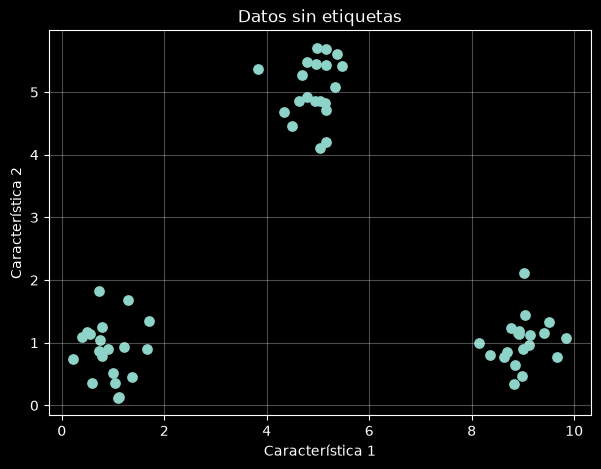

In [3]:
grupo_1 = np.random.normal(loc=[1, 1], scale=0.45, size=(20, 2))
grupo_2 = np.random.normal(loc=[5, 5], scale=0.45, size=(20, 2))
grupo_3 = np.random.normal(loc=[9, 1], scale=0.45, size=(20, 2))

X = np.vstack([grupo_1, grupo_2, grupo_3])

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], s=45)
plt.title("Datos sin etiquetas")
plt.xlabel("Característica 1")
plt.ylabel("Característica 2")
plt.grid(alpha=0.3)
plt.show()

### 2. Construir la jerarquía

`linkage` aplica el método aglomerativo: comienza con un cluster por punto y fusiona progresivamente los clusters más cercanos. `method="ward"` elige las fusiones que producen el menor aumento en la variabilidad interna. La matriz `Z` guarda el historial de fusiones.

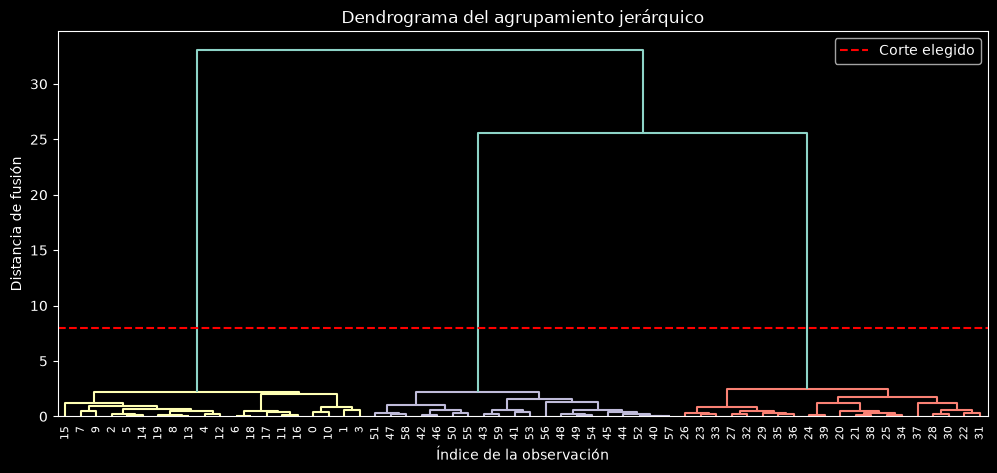

In [4]:
Z = linkage(X, method="ward")

plt.figure(figsize=(12, 5))
dendrogram(Z, leaf_rotation=90, leaf_font_size=8)
plt.title("Dendrograma del agrupamiento jerárquico")
plt.xlabel("Índice de la observación")
plt.ylabel("Distancia de fusión")
plt.axhline(y=8, color="red", linestyle="--", label="Corte elegido")
plt.legend()
plt.show()

### 3. Obtener las etiquetas de los clusters

El dendrograma permite decidir dónde cortar la jerarquía. Aquí solicitamos tres grupos mediante `criterion="maxclust"`. También se podría usar una distancia de corte con `criterion="distance"`.

In [5]:
etiquetas = fcluster(Z, t=3, criterion="maxclust")

print("Etiquetas asignadas:")
print(etiquetas)
print("\nNúmero de observaciones por cluster:")
for cluster in np.unique(etiquetas):
    print(f"Cluster {cluster}: {(etiquetas == cluster).sum()} observaciones")

Etiquetas asignadas:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3
 3 3 3 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2]

Número de observaciones por cluster:
Cluster 1: 20 observaciones
Cluster 2: 20 observaciones
Cluster 3: 20 observaciones


### 4. Visualizar el resultado

Los colores representan la etiqueta asignada por el algoritmo. Observa que el agrupamiento se realiza usando únicamente las características de `X`; las etiquetas originales de los datos simulados no se utilizan.

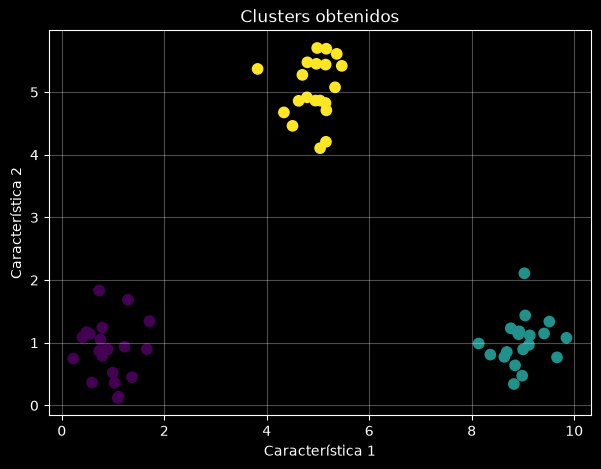

In [6]:
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=etiquetas, cmap="viridis", s=55)
plt.title("Clusters obtenidos")
plt.xlabel("Característica 1")
plt.ylabel("Característica 2")
plt.grid(alpha=0.3)
plt.show()